# 02 - Detecção de crateras

Testamos duas formas de encontrar crateras no mapa:

- **HoughCircles:** procura contornos em forma de círculo.
- **Sombra e brilho:** com o sol baixo, cada cratera aparece como uma mancha escura (sombra) ao lado de uma mancha clara (parede iluminada). O programa procura esses pares.

Para saber se o programa acertou, comparamos com o catálogo de crateras da USGS. Usamos a metade oeste do mapa para escolher os ajustes e a metade leste para testar.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt

from pouso_lunar import config
from pouso_lunar.dados import carregar_gabarito, carregar_mapa, metade
from pouso_lunar.detector import ParamsDeteccao, detectar_crateras
from pouso_lunar.metricas import casar_deteccoes

config.PASTA_RESULTADOS.mkdir(exist_ok=True)
mapa, info = carregar_mapa()
catalogo = carregar_gabarito(info)[["x", "y", "r_px"]].to_numpy()
cat_ajuste = metade(catalogo, info, "ajuste")
cat_teste = metade(catalogo, info, "teste")
print(f"crateras do catálogo: {len(cat_ajuste)} na metade oeste, {len(cat_teste)} na metade leste")


def conferir(parametros, qual="ajuste"):
    """Roda o detector e conta quantas crateras do catálogo ele achou."""
    achadas = metade(detectar_crateras(mapa, parametros), info, qual)
    cat = cat_ajuste if qual == "ajuste" else cat_teste
    r = casar_deteccoes(achadas, cat)
    return achadas, r["tp"], len(cat), len(achadas)

crateras do catálogo: 739 na metade oeste, 562 na metade leste


## Escolhendo o limiar (metade oeste)

O limiar diz o quanto um pixel precisa ser mais escuro (ou mais claro) que a vizinhança para contar como sombra (ou brilho). Testamos três valores.

In [2]:
for limiar in [12, 18, 24]:
    p = ParamsDeteccao(**{**config.PARAMS_DETECCAO, "limiar_sombra": limiar})
    _, certas, total, marcadas = conferir(p)
    print(f"limiar {limiar}: achou {certas} de {total} crateras | {certas} de {marcadas} marcações eram crateras")

limiar 12: achou 299 de 739 crateras | 299 de 1010 marcações eram crateras


limiar 18: achou 258 de 739 crateras | 258 de 463 marcações eram crateras


limiar 24: achou 171 de 739 crateras | 171 de 240 marcações eram crateras


Com limiar 12 ele marca muita coisa que não é cratera. Com 24 ele perde muitas crateras. O **18** ficou no meio e foi o escolhido.

## Resultado na metade leste

In [3]:
sombra = ParamsDeteccao(**config.PARAMS_DETECCAO)
hough = ParamsDeteccao(metodo="hough", usar_clahe=False, blur_ksize=5, acumulador=20, r_min=5, r_max=60)

achadas, certas, total, marcadas = conferir(sombra, "teste")
print(f"Sombra e brilho: achou {certas} de {total} crateras ({certas / total:.0%})")
print(f"                 {certas} de {marcadas} marcações eram crateras ({certas / marcadas:.0%})")

_, certas_h, _, marcadas_h = conferir(hough, "teste")
print(f"HoughCircles:    achou {certas_h} de {total} crateras ({certas_h / total:.0%})")
print(f"                 {certas_h} de {marcadas_h} marcações eram crateras ({certas_h / marcadas_h:.0%})")

Sombra e brilho: achou 218 de 562 crateras (39%)
                 218 de 359 marcações eram crateras (61%)


HoughCircles:    achou 114 de 562 crateras (20%)
                 114 de 1281 marcações eram crateras (9%)


O método de sombra e brilho acertou bem mais e marcou muito menos coisa errada. O HoughCircles marca círculos na textura do terreno, e a maioria não é cratera.

## Vendo na imagem

Um pedaço do mapa (metade leste). **Verde:** cratera que o programa achou. **Vermelho:** marcação que não é cratera do catálogo. **Amarelo:** cratera do catálogo que o programa não achou.

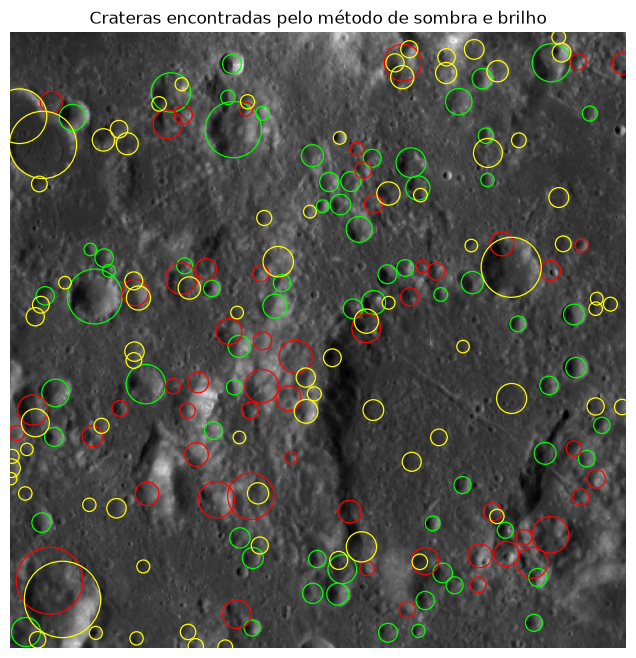

In [4]:
r = casar_deteccoes(achadas, cat_teste)
x0, y0, L = int(info.largura * 0.80), int(info.altura * 0.78), 500


def no_pedaco(c):
    return (c[:, 0] >= x0) & (c[:, 0] < x0 + L) & (c[:, 1] >= y0) & (c[:, 1] < y0 + L)


fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(mapa[y0:y0 + L, x0:x0 + L], cmap="gray")
grupos = [
    (achadas[r["mascara_det_tp"] & no_pedaco(achadas)], "lime"),
    (achadas[~r["mascara_det_tp"] & no_pedaco(achadas)], "red"),
    (cat_teste[~r["mascara_gab_tp"] & no_pedaco(cat_teste)], "yellow"),
]
for circulos, cor in grupos:
    for x, y, raio in circulos:
        ax.add_patch(plt.Circle((x - x0, y - y0), raio, fill=False, color=cor, lw=0.9))
ax.set_title("Crateras encontradas pelo método de sombra e brilho")
ax.axis("off")
fig.savefig(config.PASTA_RESULTADOS / "deteccao_exemplo.png", dpi=110, bbox_inches="tight")
plt.show()